#  Ejercicio de Evaluacion Regresion

![logo Itq](img/ITQ.png)

** NOMBRE:** Willam Pincha

*19/11/2026*

**Link del Repositorio:**<a href="https://github.com/willy2026-code/fundamentoMachineLearningNocturno/blob/main/Programa1Normalizacion.ipynb">Link Repositorio </a>

**Tema:** Evaluar un modelo SVR con los datos Diabetes de `scikit-learn`.

**Objetivo:** dividir los datos, estandarizar, validar el modelo y medir su error en datos no vistos.

## 1. Importar bibliotecas
**Concepto:** `pandas` organiza los datos en tablas (`DataFrame`); `numpy` calcula números y `scikit-learn` entrena y evalúa modelos.

In [1]:
import pandas as pd
import numpy as np
from math import sqrt
from pprint import pprint
from sklearn import datasets
#from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate
from sklearn.model_selection import KFold
from sklearn.metrics import make_scorer
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error
import matplotlib.pyplot as plt
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
import pandas as pd

## 2. Cargar y explorar los datos con pandas
**Concepto:** `as_frame=True` permite trabajar con un **DataFrame**, que organiza los registros en filas y columnas. `head()` muestra las primeras cinco filas y `shape` informa las dimensiones.

In [2]:
# Cargar y explorar los datos (como lo muestra el docente)
datos = datasets.load_diabetes(as_frame=True)
df = datos.frame

# Mostrar primeras filas y dimensiones
display(df.head())
print("Dimensiones", df.shape)
print("Nombres de columnas:", df.columns.tolist())


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


Dimensiones (442, 11)
Nombres de columnas: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'target']


## 3. Separar X e y
**Concepto:** `X` contiene las diez variables de entrada y `y` contiene el valor numérico que queremos predecir (`target`).

In [3]:
# Separar características y objetivo usando pandas
X = df.drop(columns="target")
y = df["target"]
print("Dimensión de X:", X.shape)
print("Dimensión de y:", y.shape)
display(X.head())


Dimensión de X: (442, 10)
Dimensión de y: (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


## 4. Dividir en entrenamiento y prueba
**Concepto:** entrenamos con el **80 %** y reservamos el **20 %** para comprobar el resultado final. `random_state` permite repetir la división.

In [4]:
# Partición externa: 80 % entrenamiento y 20 % prueba
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print('Entrenamiento:', X_train_raw.shape, '| Prueba:', X_test_raw.shape)

Entrenamiento: (353, 10) | Prueba: (89, 10)


## 5. Estandarizar las entradas
**Concepto:** `StandardScaler` centra las variables y ajusta su escala. Se aprende **solo con entrenamiento** para evitar fuga de información.

In [5]:
# Ajustar el escalador únicamente con los datos de entrenamiento
standardizer = StandardScaler()
X_train = standardizer.fit_transform(X_train_raw)
X_test = standardizer.transform(X_test_raw)
print('Media aproximada de entrenamiento:', np.round(X_train.mean(axis=0), 3))
print('Desviación aproximada:', np.round(X_train.std(axis=0), 3))

Media aproximada de entrenamiento: [-0. -0. -0.  0. -0. -0.  0. -0. -0.  0.]
Desviación aproximada: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 6. Definir las métricas
**Conceptos:**
- **MAE:** promedio de los errores absolutos; menor es mejor.
- **RMSE:** penaliza más los errores grandes; menor es mejor.
- **MAPE:** error porcentual medio; requiere que los valores reales no sean cero.

`cross_validate` entrega valores negativos para los errores, porque su interfaz interpreta que un valor mayor es mejor. Los convertimos a positivos al mostrarlos.

In [6]:
# Métricas de evaluación
metricas = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': make_scorer(
        lambda y_real, y_pred: sqrt(mean_squared_error(y_real, y_pred)),
        greater_is_better=False
    ),
    'MAPE': make_scorer(
        lambda y_real, y_pred: np.mean(np.abs((y_real - y_pred) / y_real)) * 100,
        greater_is_better=False
    )
}
print('Métricas:', list(metricas.keys()))

Métricas: ['MAE', 'RMSE', 'MAPE']


## 7. Crear el algoritmo SVR
**Concepto:** SVR (*Support Vector Regression*) estima valores numéricos. El núcleo RBF puede representar relaciones no lineales.

In [7]:
# Definir modelo de regresión con valores explícitos
alg = SVR(C=10, gamma='scale', kernel='rbf')
print(alg)

SVR(C=10)


## 8. Validación cruzada de 5 partes
**Concepto:** `KFold` crea cinco divisiones para comprobar el modelo en distintas porciones de entrenamiento.

**Precaución:** en cada división se vuelve a ajustar la estandarización usando solo esa parte de entrenamiento. Por eso usamos un `Pipeline` y los datos `X_train_raw`.

In [8]:
# La estandarización se realiza dentro de cada fold
pipeline_cv = make_pipeline(StandardScaler(), alg)
results = cross_validate(
    pipeline_cv,
    X_train_raw,
    y_train,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring=metricas,
    error_score='raise'
)
print('Validación cruzada completada.')

Validación cruzada completada.


## 9. Presentar resultados de la validación
**Concepto:** calculamos el promedio y la dispersión de cada error a través de los cinco pliegues.

In [9]:
# Mostrar resultados originales (negativos por convención de scikit-learn)
pprint(results)
print('Resumen en unidades positivas:')
for nombre in metricas:
    valores = -results[f'test_{nombre}']
    sufijo = '%' if nombre == 'MAPE' else ''
    print(f'{nombre}: {valores.mean():.2f}{sufijo} ± {valores.std():.2f}{sufijo}')

{'fit_time': array([0.00544333, 0.00356555, 0.00434756, 0.0036912 , 0.00377202]),
 'score_time': array([0.00240684, 0.00212002, 0.00192833, 0.00198865, 0.00180721]),
 'test_MAE': array([-48.26285616, -51.99094138, -42.19909846, -45.73437715,
       -50.39789838]),
 'test_MAPE': array([-32.83110657, -45.90028442, -37.74947192, -43.12401136,
       -44.16570536]),
 'test_RMSE': array([-57.68310314, -60.27338482, -51.94585761, -55.51382769,
       -63.98279561])}
Resumen en unidades positivas:
MAE: 47.72 ± 3.47
RMSE: 57.88 ± 4.09
MAPE: 40.75% ± 4.81%


## 10. Entrenar el modelo final
**Concepto:** luego de validar, entrenamos con todos los datos de entrenamiento y dejamos intactos los datos de prueba.

Los parámetros `C=10`, `gamma='scale'` y `kernel='rbf'` vienen del notebook original. **No se ha realizado una búsqueda de hiperparámetros.**

In [10]:
# Entrenar modelo final con el conjunto de entrenamiento estandarizado
model = SVR(C=10, gamma='scale', kernel='rbf')
model.fit(X_train, y_train)
print('Modelo final entrenado.')

Modelo final entrenado.


## 11. Predecir y calcular errores en prueba
**Concepto:** el MAE resume cuánto se alejan, en promedio, las predicciones de los valores reales.

In [11]:
# Predecir los valores del conjunto de prueba
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = sqrt(mean_squared_error(y_test, y_pred))
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
print('Test MAE:', round(mae, 2))
print('Test RMSE:', round(rmse, 2))
print('Test MAPE:', round(mape, 2), '%')

Test MAE: 41.32
Test RMSE: 51.79
Test MAPE: 36.34 %


## 12. Comparar valores reales y estimados con pandas
**Concepto:** la tabla reúne cada valor real, su predicción y el error absoluto para comprender las diferencias.

In [12]:
# Crear una tabla de comparación
comparacion = pd.DataFrame({
    "Real": np.asarray(y_test),
    "Predicción": y_pred,
})
comparacion["Error absoluto"] = (comparacion["Real"] - comparacion["Predicción"]).abs()
display(comparacion.head(10).round(2))


,Real,Predicción,Error absoluto
0,219.0,149.01,69.99
1,70.0,172.17,102.17
2,202.0,152.87,49.13
3,230.0,212.28,17.72
4,111.0,110.07,0.93
5,84.0,122.34,38.34
6,242.0,227.34,14.66
7,272.0,191.77,80.23
8,94.0,106.74,12.74
9,96.0,103.85,7.85


## 13. Graficar valores reales frente a predicciones
**Concepto:** cada punto representa un registro. La línea diagonal indica una predicción perfecta; puntos lejanos tienen mayor error.

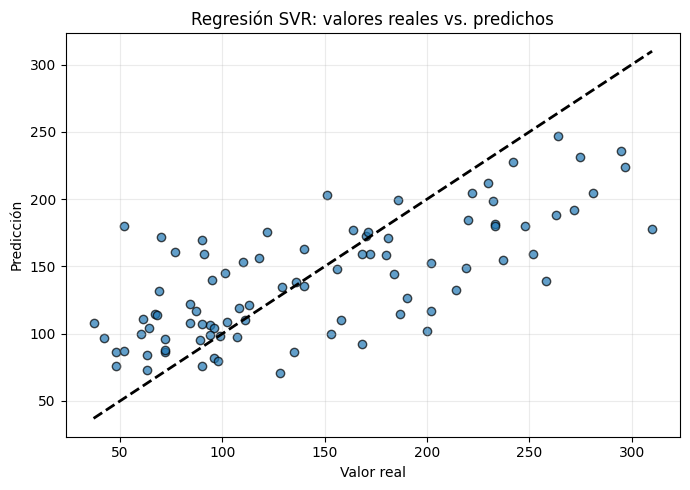

In [13]:
# Gráfico real vs predicción
def grafica_real_vs_pred(y_true, y_pred, metricas, algoritmo):
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(y_true, y_pred, edgecolors='black', alpha=0.7)
    minimo = min(np.min(y_true), np.min(y_pred))
    maximo = max(np.max(y_true), np.max(y_pred))
    ax.plot([minimo, maximo], [minimo, maximo], 'k--', lw=2)
    ax.set_xlabel('Valor real')
    ax.set_ylabel('Predicción')
    ax.set_title('Regresión SVR: valores reales vs. predichos')
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

grafica_real_vs_pred(y_test, y_pred, metricas, model)

## 14. Comparar con un modelo básico
**Concepto:** `DummyRegressor` predice siempre el promedio del entrenamiento. Sirve como referencia para saber si el modelo SVR mejora una solución simple.

In [14]:
baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)
pred_baseline = baseline.predict(X_test)
mae_baseline = mean_absolute_error(y_test, pred_baseline)
print(f'MAE modelo básico: {mae_baseline:.2f}')
print(f'MAE SVR: {mae:.2f}')
print('SVR mejora el MAE básico:', mae < mae_baseline)

MAE modelo básico: 64.01
MAE SVR: 41.32
SVR mejora el MAE básico: True


## 15. Conclusiones
- **Regresión** busca predecir valores numéricos, no clases.
- **Estandarización** ayuda al SVR a trabajar con las variables en escalas comparables.
- **Validación cruzada** calcula el error en varias divisiones de entrenamiento.
- **Conjunto de prueba** sirve para estimar el rendimiento final con datos separados.
- **MAE, RMSE y MAPE** muestran distintos aspectos del error; los valores concretos se calculan al ejecutar las celdas.

**Nota académica:** el conjunto `load_diabetes` es de aprendizaje; sus resultados no deben utilizarse para decisiones médicas reales.

**Asistencia:** código completado y conceptos breves redactados con ayuda de ChatGPT, a partir del archivo proporcionado.